# GANs: Generative Adversarial Networks (Goodfellow et al., 2014)

The [VAE](/how-models-work/vae-auto-encoding-variational-bayes/) trains a
generator by maximising a likelihood bound, and pays for it with blurry samples.
This paper skipped likelihoods entirely. Train a **generator** $G$ to turn noise
into samples, and a **discriminator** $D$ to tell real samples from generated
ones. Then let them compete:

$$\min_G \max_D \; V(D, G) = \mathbb{E}_{x \sim p_{data}}[\log D(x)] + \mathbb{E}_{z \sim p_z}[\log(1 - D(G(z)))]$$

$D$ wants to output 1 on real data and 0 on fakes. $G$ wants its fakes to be
scored as real. Nobody ever writes down a density for the generator. It only
has to produce samples, and the discriminator's gradient tells it how to make
them more realistic.

1. The optimal discriminator, derived and checked numerically
2. What the game minimises: Jensen–Shannon divergence, checked
3. Why the paper changes the generator's loss in practice
4. Training a real GAN in 1-D, frame by frame
5. Mode collapse and what came after

In [1]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from hmw_motion import Scene, mix

torch.manual_seed(0); np.random.seed(0)
torch.set_num_threads(4)
np.set_printoptions(precision=4, suppress=True, linewidth=120)


def banner(title):
    print("=" * 78); print(f"  {title}"); print("=" * 78)


def step(label):
    print(); print(label); print("-" * 78)


def check(label, ok):
    print(f"  [{'PASS' if ok else 'FAIL'}] {label}")
    return ok


def npdf(x, m, s):
    return np.exp(-(x - m) ** 2 / (2 * s * s)) / (s * np.sqrt(2 * np.pi))


print("helpers ready")

helpers ready


## 1. The optimal discriminator

Fix the generator, so its samples follow some density $p_g$. Writing $V$ as one
integral over $x$:

$$V = \int \big[p_{data}(x)\log D(x) + p_g(x)\log(1 - D(x))\big]\,dx$$

$D(x)$ can be chosen separately at every $x$. For $a\log y + b\log(1-y)$, the
maximum is at $y = a/(a+b)$. So the best possible discriminator is

$$D^*(x) = \frac{p_{data}(x)}{p_{data}(x) + p_g(x)}$$

It says 1 where only real data lives, 0 where only fakes live, and ½ where the
two are equally likely. The cell checks this by **maximising $V$ numerically**,
with gradient ascent on a free logit at each of 200 grid points, and comparing
the result to the formula. Because the objective splits by $x$, each point gets
its own step size, so the far tails converge as fast as the centre.

In [2]:
banner("D* = p_data / (p_data + p_g), BY OPTIMISATION")
xg = np.linspace(-5, 5, 200)
dx = xg[1] - xg[0]
p_data = 0.5 * npdf(xg, -1.5, 0.6) + 0.5 * npdf(xg, 1.5, 0.6)
p_g = npdf(xg, 0.5, 1.2)
logit = np.zeros_like(xg)
for _ in range(2000):
    Dv = 1 / (1 + np.exp(-logit))
    grad = p_data * (1 - Dv) - p_g * Dv          # dV/dlogit at each x
    # V splits into a separate problem at each x, so each point may take its own
    # step size; scaling by 1/(p_data + p_g) keeps the far tails from stalling
    logit += 2.0 * grad / (p_data + p_g)
D_opt = 1 / (1 + np.exp(-logit))
D_formula = p_data / (p_data + p_g)
print(f"  max |D_optimised - D_formula| over the grid: {np.abs(D_opt - D_formula).max():.2e}")
check("gradient ascent on V lands on p_data / (p_data + p_g)", np.abs(D_opt - D_formula).max() < 1e-3)
for xv in [-1.5, 0.0, 0.5, 3.0]:
    i = np.argmin(np.abs(xg - xv))
    print(f"  x = {xg[i]:+.2f}:  p_data {p_data[i]:.4f}   p_g {p_g[i]:.4f}   D* {D_formula[i]:.4f}")

  D* = p_data / (p_data + p_g), BY OPTIMISATION
  max |D_optimised - D_formula| over the grid: 2.28e-04
  [PASS] gradient ascent on V lands on p_data / (p_data + p_g)
  x = -1.48:  p_data 0.3323   p_g 0.0849   D* 0.7964
  x = -0.03:  p_data 0.0293   p_g 0.3021   D* 0.0885
  x = +0.48:  p_data 0.0793   p_g 0.3324   D* 0.1925
  x = +2.99:  p_data 0.0152   p_g 0.0386   D* 0.2828


## 2. What the generator is really minimising

Substitute $D^*$ back into $V$ and the generator's objective becomes, as the
paper shows,

$$C(G) = \max_D V(D, G) = -\log 4 + 2\cdot \mathrm{JSD}(p_{data} \,\|\, p_g)$$

The Jensen–Shannon divergence is zero only when the two distributions are
equal. So the game has a unique optimum: **$p_g = p_{data}$**, where $D^* = ½$
everywhere and $V = -\log 4 \approx -1.386$. The cell checks the identity for
several generators.

In [3]:
banner("max_D V  ==  -log 4 + 2 * JSD")


from scipy.special import xlogy          # xlogy(0, 0) = 0, as the integrals require


def V_at_opt(pd, pg):
    D, one_minus_D = pd / (pd + pg), pg / (pd + pg)     # 1 - D computed directly: no 1 - (1 - 1e-26)
    return np.sum(xlogy(pd, D) + xlogy(pg, one_minus_D)) * dx


def jsd(pd, pg):
    m = 0.5 * (pd + pg)
    kl = lambda a, b: np.sum(xlogy(a, a) - xlogy(a, b)) * dx
    return 0.5 * kl(pd, m) + 0.5 * kl(pg, m)


norm = lambda p: p / (p.sum() * dx)        # the identity needs densities that integrate to 1 on the grid
worst = 0
for name, pg in [("wide Gaussian", npdf(xg, 0.5, 1.2)), ("one mode only", npdf(xg, 1.5, 0.6)),
                 ("close", 0.5 * npdf(xg, -1.4, 0.65) + 0.5 * npdf(xg, 1.6, 0.6)), ("exact", p_data.copy())]:
    pd_, pg = norm(p_data), norm(pg)
    v, j = V_at_opt(pd_, pg), jsd(pd_, pg)
    worst = max(worst, abs(v - (-np.log(4) + 2 * j)))
    print(f"  {name:<14} max_D V = {v:+.5f}   -log4 + 2*JSD = {-np.log(4) + 2*j:+.5f}   JSD = {j:.5f}")
check("identity holds for every generator tried (to 1e-9)", worst < 1e-9)
print(f"  largest discrepancy: {worst:.1e}")
print(f"  at p_g = p_data:  V = {-np.log(4):.5f} = -log 4")

  max_D V  ==  -log 4 + 2 * JSD
  wide Gaussian  max_D V = -1.14444   -log4 + 2*JSD = -1.14444   JSD = 0.12093
  one mode only  max_D V = -0.96691   -log4 + 2*JSD = -0.96691   JSD = 0.20969
  close          max_D V = -1.38015   -log4 + 2*JSD = -1.38015   JSD = 0.00307
  exact          max_D V = -1.38629   -log4 + 2*JSD = -1.38629   JSD = 0.00000
  [PASS] identity holds for every generator tried (to 1e-9)
  largest discrepancy: 2.2e-16
  at p_g = p_data:  V = -1.38629 = -log 4


In [4]:
def jsd_scene():
    sc = Scene(720, 380, dur=9.0, caption="As p_g approaches p_data, D* flattens to 1/2 and JSD falls to 0",
               poster=8.5)
    X0, X1, Y0 = 40, 470, 300
    px = lambda v: X0 + (v + 5) / 10 * (X1 - X0)
    sc.line(X0, Y0, X1, Y0, stroke="grid", sw=1.5)
    sc.line(X0, Y0 - 230, X1, Y0 - 230, stroke="grid", sw=1, dash="3 5")
    sc.text(X1 + 4, Y0 - 230, "D = 1", size=10, fill="muted", anchor="start")
    sc.line(X0, Y0 - 115, X1, Y0 - 115, stroke="grid", sw=1, dash="3 5")
    sc.text(X1 + 4, Y0 - 115, "D = 1/2", size=10, fill="muted", anchor="start")
    ys = 300
    pts = lambda arr, sc_: [v for k in range(0, len(xg), 2) for v in (px(xg[k]), Y0 - arr[k] * sc_)]
    sc.poly(pts(p_data, ys), stroke="green", sw=3)
    pg0 = npdf(xg, 0.5, 1.2)
    G = sc.poly(pts(pg0, ys), stroke="pink", sw=3)
    Dl = sc.poly(pts(p_data / (p_data + pg0), 230), stroke="amber", sw=2.5, dash="7 4")
    sc.text(60, 30, "p_data", size=13, fill="green", anchor="start", weight=700)
    sc.text(140, 30, "p_g", size=13, fill="pink", anchor="start", weight=700)
    sc.text(200, 30, "D*(x)", size=13, fill="amber", anchor="start", weight=700)
    RX = 520
    jn = sc.num(RX, 120, jsd(p_data, pg0), dec=4, pre="JSD = ", size=16, fill="text", anchor="start")
    vn = sc.num(RX, 160, V_at_opt(p_data, pg0), dec=4, pre="V = ", size=16, fill="amber", anchor="start")
    sc.text(RX, 196, f"minimum: -log 4 = {-np.log(4):.4f}", size=12, fill="muted", anchor="start")
    t = 0.8
    for a in np.linspace(0, 1, 9)[1:]:
        pg = (1 - a) * pg0 + a * p_data
        G.to(t, t + 0.8, pts=pts(pg, ys))
        Dl.to(t, t + 0.8, pts=pts(p_data / (p_data + pg), 230))
        jn.to(t, t + 0.8, v=jsd(p_data, pg)); vn.to(t, t + 0.8, v=V_at_opt(p_data, pg))
        t += 0.9
    sc.beat(0.0, "Where fakes are common, D* is low; where only real data lives, D* is near 1.")
    sc.beat(3.0, "Blend the generator toward the data: the discriminator has less and less to go on.")
    sc.beat(7.6, "At p_g = p_data, D* = 1/2 everywhere and V reaches its minimum, -log 4.")
    return sc

jsd_scene()

<motion scene: As p_g approaches p_data, D* flattens to 1/2 and JSD falls to 0 (14 elements, 9s)>

## 3. The loss the paper actually trains with

Early in training the generator is bad and the discriminator rejects its
samples confidently: $D(G(z)) \approx 0$. In that region $\log(1 - D(G(z)))$ is
nearly flat, so the generator gets almost no gradient exactly when it needs it
most. The paper's fix is to have the generator **maximise $\log D(G(z))$**
instead. It has the same fixed point and much stronger gradients early on. This
"non-saturating" loss is what practically every GAN uses.

The gradient with respect to the discriminator's logit $\ell$, where
$D = \sigma(\ell)$, makes the difference concrete.

  SATURATING vs NON-SATURATING GENERATOR LOSS
  D(G(z)) = 0.001   gradient of log(1-D): -0.0010   gradient of log D: +0.9990   ratio   999.0x
  D(G(z)) = 0.01    gradient of log(1-D): -0.0100   gradient of log D: +0.9900   ratio    99.0x
  D(G(z)) = 0.1     gradient of log(1-D): -0.1000   gradient of log D: +0.9000   ratio     9.0x
  D(G(z)) = 0.5     gradient of log(1-D): -0.5000   gradient of log D: +0.5000   ratio     1.0x
  D(G(z)) = 0.9     gradient of log(1-D): -0.9000   gradient of log D: +0.1000   ratio     0.1x


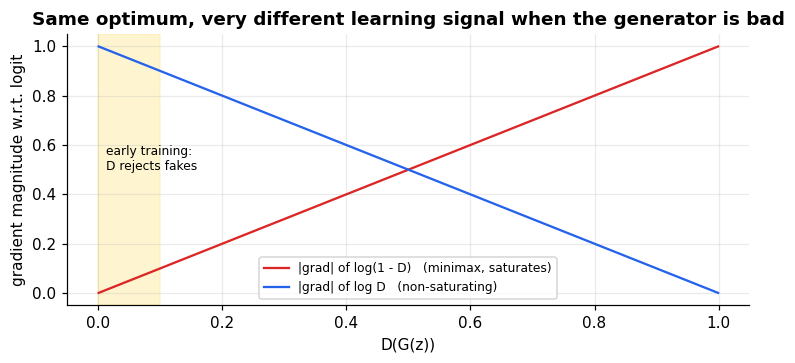

In [5]:
banner("SATURATING vs NON-SATURATING GENERATOR LOSS")
for Dv in [0.001, 0.01, 0.1, 0.5, 0.9]:
    g_sat = -Dv                 # d/dl log(1 - sigmoid(l)) = -sigmoid(l)
    g_ns = 1 - Dv               # d/dl log sigmoid(l) = 1 - sigmoid(l)
    print(f"  D(G(z)) = {Dv:<6}  gradient of log(1-D): {g_sat:+.4f}   gradient of log D: {g_ns:+.4f}   "
          f"ratio {abs(g_ns/g_sat):7.1f}x")
Ds = np.linspace(0.001, 0.999, 300)
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(Ds, Ds, color="#dc2626", label="|grad| of log(1 - D)   (minimax, saturates)")
ax.plot(Ds, 1 - Ds, color="#2563eb", label="|grad| of log D   (non-saturating)")
ax.axvspan(0, 0.1, color="#fde68a", alpha=0.4); ax.text(0.012, 0.5, "early training:\nD rejects fakes", fontsize=8)
ax.set_xlabel("D(G(z))"); ax.set_ylabel("gradient magnitude w.r.t. logit")
ax.set_title("Same optimum, very different learning signal when the generator is bad"); ax.legend(fontsize=8)

## 4. Training a GAN in one dimension

The target is a two-peaked distribution. The generator is a small MLP that turns
8-dimensional Gaussian noise into one number. The discriminator is a small MLP
that turns one number into a probability. They alternate updates with Adam
(learning rate $2\times10^{-4}$, $\beta_1 = 0.5$, the DCGAN settings) and the
non-saturating loss, as in the paper's Algorithm 1 with $k = 1$. These settings
were chosen after trial runs: at a learning rate of $10^{-3}$ the generator's
distance to the data kept oscillating between about 0.2 and 0.5 instead of
settling. GANs are sensitive to this, as the next section explains.

Every 150 steps the cell records the generator's density, estimated from 20,000
samples, and the discriminator's output across the line. Those snapshots drive
the animation below.

  TRAINING
  step    0:  D loss 1.414   G loss 0.743   generator mean +0.187  std 0.056
  step  600:  D loss 1.325   G loss 0.735   generator mean +0.001  std 1.628
  step 1500:  D loss 1.397   G loss 0.702   generator mean -0.008  std 1.554
  step 6000:  D loss 1.389   G loss 0.693   generator mean -0.003  std 1.576

Final generator vs data
------------------------------------------------------------------------------
  data       share below 0: 0.503   mean -0.007   std 1.613
  generator  share below 0: 0.501   mean -0.003   std 1.576
  Wasserstein-1 distance to the data: 1.458 at step 0  ->  0.036 at the end
  [PASS] the generator ends far closer to the data than it started (W1 shrinks by > 5x)
  [PASS] both modes are covered (each holds 35-65% of samples)
  discriminator output on [-3, 3] at the end: min 0.440  max 0.506  (1/2 would be a perfect tie)
  distance along the way: best 0.029 at step 3000; after step 750 it still swung as high as 0.260


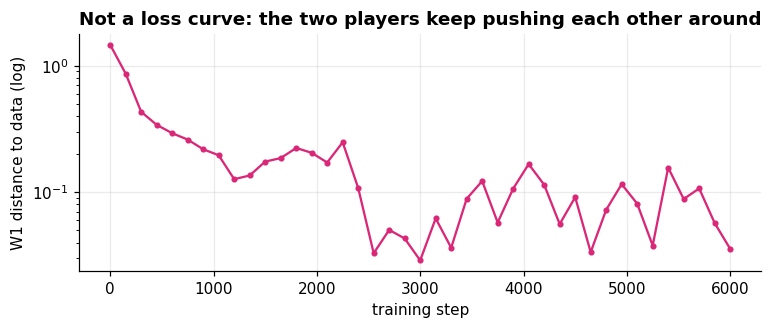

In [6]:
banner("TRAINING")
torch.manual_seed(0)
NZ = 8


def sample_data(n):
    c = torch.randint(0, 2, (n, 1)).float()
    return (c * 2 - 1) * 1.5 + 0.6 * torch.randn(n, 1)


G = nn.Sequential(nn.Linear(NZ, 64), nn.LeakyReLU(0.2), nn.Linear(64, 64), nn.LeakyReLU(0.2), nn.Linear(64, 1))
D = nn.Sequential(nn.Linear(1, 64), nn.LeakyReLU(0.2), nn.Linear(64, 64), nn.LeakyReLU(0.2), nn.Linear(64, 1))
oG = torch.optim.Adam(G.parameters(), lr=2e-4, betas=(0.5, 0.999))
oD = torch.optim.Adam(D.parameters(), lr=2e-4, betas=(0.5, 0.999))
bce = nn.BCEWithLogitsLoss()
grid = torch.linspace(-5, 5, 121)[:, None]


def density(samples, bw=0.18):
    s = samples.numpy().ravel()
    gx = grid.numpy().ravel()
    return np.exp(-(gx[:, None] - s[None]) ** 2 / (2 * bw * bw)).sum(1) / (len(s) * bw * np.sqrt(2 * np.pi))


snaps = []
from scipy.stats import wasserstein_distance
ds = sample_data(20000).numpy().ravel()
for it in range(0, 6001):
    real = sample_data(256)
    fake = G(torch.randn(256, NZ))
    lossD = bce(D(real), torch.ones(256, 1)) + bce(D(fake.detach()), torch.zeros(256, 1))
    oD.zero_grad(); lossD.backward(); oD.step()
    lossG = bce(D(fake), torch.ones(256, 1))                 # non-saturating: maximise log D(G(z))
    oG.zero_grad(); lossG.backward(); oG.step()
    if it % 150 == 0:
        with torch.no_grad():
            gs = G(torch.randn(20000, NZ))
            snaps.append((it, density(gs), torch.sigmoid(D(grid)).numpy().ravel(), gs.numpy().ravel(),
                          wasserstein_distance(gs.numpy().ravel(), ds)))
        if it in (0, 600, 1500, 6000):
            print(f"  step {it:>4}:  D loss {lossD.item():.3f}   G loss {lossG.item():.3f}   "
                  f"generator mean {gs.mean():+.3f}  std {gs.std():.3f}")

step("Final generator vs data")
gs = snaps[-1][3]
for name, arr in [("data", ds), ("generator", gs)]:
    print(f"  {name:<10} share below 0: {(arr < 0).mean():.3f}   mean {arr.mean():+.3f}   std {arr.std():.3f}")
w0, w1 = snaps[0][4], snaps[-1][4]
print(f"  Wasserstein-1 distance to the data: {w0:.3f} at step 0  ->  {w1:.3f} at the end")
check("the generator ends far closer to the data than it started (W1 shrinks by > 5x)", w1 < w0 / 5)
check("both modes are covered (each holds 35-65% of samples)", 0.35 < (gs < 0).mean() < 0.65)
D_end = snaps[-1][2]
inner = (grid.numpy().ravel() > -3) & (grid.numpy().ravel() < 3)
print(f"  discriminator output on [-3, 3] at the end: min {D_end[inner].min():.3f}  max {D_end[inner].max():.3f}"
      f"  (1/2 would be a perfect tie)")
wtraj = np.array([(sn[0], sn[4]) for sn in snaps])
print(f"  distance along the way: best {wtraj[:, 1].min():.3f} at step {int(wtraj[wtraj[:, 1].argmin(), 0])}; "
      f"after step {int(wtraj[5, 0])} it still swung as high as {wtraj[5:, 1].max():.3f}")
fig, ax = plt.subplots(figsize=(8, 2.8))
ax.plot(wtraj[:, 0], wtraj[:, 1], "o-", ms=3, color="#db2777")
ax.set_yscale("log"); ax.set_xlabel("training step"); ax.set_ylabel("W1 distance to data (log)")
ax.set_title("Not a loss curve: the two players keep pushing each other around")

In [7]:
def train_scene():
    sc = Scene(720, 390, dur=0.8 + len(snaps) * 0.32 + 0.6,
               caption="The 1-D GAN trained above: generator density (pink) and discriminator D(x) (amber)",
               poster=0.8 + len(snaps) * 0.32)
    X0, X1, Y0 = 40, 680, 320
    gx = grid.numpy().ravel()
    px = lambda v: X0 + (v + 5) / 10 * (X1 - X0)
    sc.line(X0, Y0, X1, Y0, stroke="grid", sw=1.5)
    for k in range(-4, 5, 2):
        sc.text(px(k), Y0 + 16, str(k), size=11, fill="muted")
    sc.line(X0, Y0 - 120, X1, Y0 - 120, stroke="grid", sw=1, dash="3 5")
    sc.text(X1 + 2, Y0 - 120, "1/2", size=10, fill="muted", anchor="start")
    ys = 330
    true_d = 0.5 * npdf(gx, -1.5, 0.6) + 0.5 * npdf(gx, 1.5, 0.6)
    sc.poly([v for i in range(len(gx)) for v in (px(gx[i]), Y0 - true_d[i] * ys)], stroke="green", sw=2.5,
            fill="#34d39922")
    ptsG = lambda dd: [v for i in range(len(gx)) for v in (px(gx[i]), Y0 - min(dd[i], 0.95) * ys)]
    ptsD = lambda dd: [v for i in range(len(gx)) for v in (px(gx[i]), Y0 - dd[i] * 240)]
    Gp = sc.poly(ptsG(snaps[0][1]), stroke="pink", sw=3)
    Dp = sc.poly(ptsD(snaps[0][2]), stroke="amber", sw=2, dash="6 4")
    itn = sc.num(X1, 30, 0, dec=0, pre="step ", size=15, fill="text", anchor="end")
    sc.text(X0, 30, "data", size=13, fill="green", anchor="start", weight=700)
    sc.text(X0 + 52, 30, "generator", size=13, fill="pink", anchor="start", weight=700)
    sc.text(X0 + 140, 30, "D(x)", size=13, fill="amber", anchor="start", weight=700)
    for k in range(1, len(snaps)):
        t0, t1 = 0.8 + (k - 1) * 0.32, 0.8 + k * 0.32
        Gp.to(t0, t1, pts=ptsG(snaps[k][1]), ease="lin")
        Dp.to(t0, t1, pts=ptsD(snaps[k][2]), ease="lin")
        itn.to(t0, t1, v=snaps[k][0], ease="lin")
    sc.beat(0.0, "Step 0: the untrained generator puts all its mass in a narrow lump.")
    sc.beat(1.5, "D(x) rises where real data is and falls where the fakes are; G follows D's slope.")
    sc.beat(5.5, "The generator spreads toward both modes as the discriminator keeps pointing the way.")
    sc.beat(10.5, "Near the end D(x) hovers around 1/2 over the data: it can barely tell them apart.")
    return sc

train_scene()

<motion scene: The 1-D GAN trained above: generator density (pink) and discriminator D(x) (amber) (15 elements, 14.52s)>

## 5. Mode collapse, and what came after

The theory assumes $D$ is trained to optimality at every step and that the
model has unlimited capacity. Neither holds in practice, and GAN training
became famous for being unstable. The most notorious failure is **mode
collapse**. The generator finds one output the discriminator currently accepts
and produces only that. The discriminator adapts, the generator jumps to another
single mode, and the two chase each other around. Small runs like the one above
can show partial versions of this: one mode filled before the other, or
temporary oscillations visible in the animation.

A decade of follow-up work went into stability and quality:

* **DCGAN** (2015): convolutional architecture guidelines that made image GANs
  train reliably.
* **WGAN** (2017): replaces the JS divergence with the Wasserstein distance,
  which gives useful gradients even when the two distributions do not overlap.
* **StyleGAN** (2019–2021): style-based generators with photorealistic faces.

For most image generation, GANs have since been overtaken by **diffusion
models** (next page), which are slower to sample from but far more stable to
train and better at covering every mode. GAN-style adversarial losses survive
inside other systems, such as the decoder of the autoencoder used by Stable
Diffusion.

## Summary

* Two networks play a minimax game: $D$ separates real from fake, and $G$ tries
  to fool $D$. No density for $G$ is ever written down.
* The optimal discriminator is $p_{data}/(p_{data}+p_g)$, found here by direct
  optimisation to within $10^{-3}$.
* At that discriminator the game value is $-\log 4 + 2\,\mathrm{JSD}$, checked to
  $10^{-9}$, so the global optimum is $p_g = p_{data}$.
* The non-saturating generator loss $-\log D(G(z))$ has the same optimum and
  gradients up to hundreds of times larger early in training.
* A 1-D GAN trained here moved from a narrow lump to both modes of the target.
  The Wasserstein distance to the data shrank by more than 5×, though not
  monotonically, and the discriminator ended near ½.